# Phase25D canonical reviewer audit — notebook compliance repair

Analysis of frozen artifacts only. Scientific execution is accepted and unchanged. Phase25E remains ELIGIBLE_NOT_STARTED. No holdout, VAL808 or TEST outcomes are read.

PRE_NOTEBOOK_COMPLIANCE_REPAIR_PROVENANCE = `29518fc13f3de60113e1110a12a3f38bac5f54c246751503fe29e595f6dbe997`

All code cells execute during each build; execution counts are retained. No output is preattached. Only execution timing metadata is disabled. Tables include every persisted column and every epoch. Persisted `is_best` marks running improvements; the last improvement is the canonical selected best.

Fold3: 200 completed epochs, selected best 199, termination `max_epochs`. The earlier 199-total summary was CHAT_OR_SUMMARY_TRANSCRIPTION_DEFECT_ONLY.

In [1]:
from pathlib import Path
import hashlib, json, io
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'reports/audits/phase25d_final_freeze.json').exists())
INPUTS = {'checkpoints/phase25d_barr_benefit_router_v1_2_1_seed42/final/final.pt': '8a412b2fe82f225f844fda07379a6436c1d73d435f885b26a1d88d5b2f9fc43b', 'data_cache/phase25b_barr_pre_refinement_features_v1_2/feature_schema.csv': 'da76aa34f14006146f46ca799f173378274d8c9d0792dc18edb30711a2486dd4', 'data_cache/phase25b_barr_pre_refinement_features_v1_2/features.npy': '9c241963b54f23de1c9671ff6670dde7d6f7e2510869ef5ebc1baf3f7c833e0a', 'data_cache/phase25b_barr_pre_refinement_features_v1_2/metadata.csv': 'ee8c304350d28d907c053a355da1f878ff7f9dd137761034283459aeed071093', 'data_cache/phase25c_barr_oof_paired_gain_labels_v1_2/phase25c_oof_paired_gain_labels.csv': 'fd6ca32c33a3bddb75f986b1350d54ec35b11d3bf5cb0fdc029962a5aa94865f', 'data_cache/phase25d_barr_benefit_router_v1_2_1/phase25d_oof_router_predictions.csv': '837be08e569053676b71d1ab216ff604184b2b61df567cca45e6f8a5546d4441', 'experiments/phase25d_barr_benefit_router_v1_2_1_seed42/final/history.csv': 'a5f1c8bc95da53fc8ba3cca794339a380c9354c3e4095f8fcd69a503edb39247', 'experiments/phase25d_barr_benefit_router_v1_2_1_seed42/fold0/history.csv': '1b5bfa6136b00172458b2a09f64e1402883b79e1354765cb49c42577e2e1695a', 'experiments/phase25d_barr_benefit_router_v1_2_1_seed42/fold0/training_closure.json': '693e762aed8afab36fea6ee702187885a731c8a5b260aaa35f9a0868b86b8bc3', 'experiments/phase25d_barr_benefit_router_v1_2_1_seed42/fold1/history.csv': '0a3102c81aa2c30ea922ddc19f38fd67c0a6bd73aefaff1c664ef059bec54488', 'experiments/phase25d_barr_benefit_router_v1_2_1_seed42/fold1/training_closure.json': '7820c58934e41e6556985c39f4edddb5d3de88a4c38d399b28f810bf7a4c974a', 'experiments/phase25d_barr_benefit_router_v1_2_1_seed42/fold2/history.csv': '7a98beff501b3266d89062cdb1b69197b983a2b5c5c3542f9fd4a60ea9a80b3a', 'experiments/phase25d_barr_benefit_router_v1_2_1_seed42/fold2/training_closure.json': '1ea89f449ee79d2f1b2ed08b078219327f20f811eeca005f15fef57f0bd1c85e', 'experiments/phase25d_barr_benefit_router_v1_2_1_seed42/fold3/history.csv': 'e159168f90b33cbad45a157902a78e498296b2a0dee30a731ee5024526479203', 'experiments/phase25d_barr_benefit_router_v1_2_1_seed42/fold3/training_closure.json': '74f7881f01963fee3734906ea2fb79aff8c467389143e6ecc6f06025afcb4e77', 'experiments/phase25d_barr_benefit_router_v1_2_1_seed42/fold4/history.csv': '5d4fe57797753e5c77ef3657bc16573f570a8d352bfb7f7c3a4032c35b45902d', 'experiments/phase25d_barr_benefit_router_v1_2_1_seed42/fold4/training_closure.json': '2b7d890fbc8606b10ea0ad8fd040a908e1585d1c677761a87d4bb81545b3ccba', 'reports/audits/phase25d_final_freeze.json': '813a0c37b073c3b65a79340500b14a295b718b1e08ba91959176f5b62746afe5', 'reports/audits/phase25d_final_refit_epoch_rule_execution.json': 'f1c14020e8e79b377d3c330df6b729f18ef7bdaaedb483a63999a556dd3da408', 'reports/tables/phase25d_checkpoint_inventory.csv': '626198cc4938abadeca53eeef25a79192b8080a77e07c07c65a674f820884d21', 'reports/tables/phase25d_cv5_manifest.csv': '008b92963664f38e84f33c771cea1db90caae02a366f02b6a83635a535639707', 'reports/tables/phase25d_cv5_manifest_summary.csv': 'cb3cd666c1d562de31df22a793e692b0aae976ac16f0aded796ee67bb184f7f3', 'reports/tables/phase25d_cv_fold0_early_stop_ids.csv': 'a602cbe2530356da934a628764d8dfc95e2e8145a0320615be5228db0b90ec42', 'reports/tables/phase25d_cv_fold0_fit_ids.csv': 'e78552ad7dac4108d976472903ba8d57386f26639e84f9aed0f8c09ac8eb73a3', 'reports/tables/phase25d_cv_fold0_outer_target_ids.csv': 'f7209b141d0b33dfe6570114d4fba4cd1503dcd07f9edc5f9bc8d808a315e7cd', 'reports/tables/phase25d_cv_fold0_training_history.csv': '1b5bfa6136b00172458b2a09f64e1402883b79e1354765cb49c42577e2e1695a', 'reports/tables/phase25d_cv_fold1_early_stop_ids.csv': '146fe774cad99de2960a3cdc3cbdc344d75770dde6447ee8d8fc84608f168300', 'reports/tables/phase25d_cv_fold1_fit_ids.csv': 'd6f67df55fe67af41e637e18ae66d0e46df654771d39eae9694bffd824627a4b', 'reports/tables/phase25d_cv_fold1_outer_target_ids.csv': 'cac7971ca8b5fcd056bf2f0472426926779ff0cc198b303692afbcbabab24b03', 'reports/tables/phase25d_cv_fold1_training_history.csv': '0a3102c81aa2c30ea922ddc19f38fd67c0a6bd73aefaff1c664ef059bec54488', 'reports/tables/phase25d_cv_fold2_early_stop_ids.csv': 'd0fc38e7efb3dcc43f2f1ec8626a9e8c3aec60d49c6438476b4d22b2133741bf', 'reports/tables/phase25d_cv_fold2_fit_ids.csv': '45a3af35f7079d9edc837423719bb77b910e691b1a4d3a2a7a68a0c91dc86fc7', 'reports/tables/phase25d_cv_fold2_outer_target_ids.csv': '8205316a0db4d837518c432400e0b637b38ad4accb08d70e2d9468cd2e7acabf', 'reports/tables/phase25d_cv_fold2_training_history.csv': '7a98beff501b3266d89062cdb1b69197b983a2b5c5c3542f9fd4a60ea9a80b3a', 'reports/tables/phase25d_cv_fold3_early_stop_ids.csv': 'd22f07701e3340e3c676795561ea15a2f028443d7395f041aad0907617dd6fef', 'reports/tables/phase25d_cv_fold3_fit_ids.csv': '409922e3959d69d1abd1d9e025169c60f336b140438d02cfbc1e98e06bf5d209', 'reports/tables/phase25d_cv_fold3_outer_target_ids.csv': '391897f9533075844a43483666d92f248d918804e7602e249f1db504cf5e2e52', 'reports/tables/phase25d_cv_fold3_training_history.csv': 'e159168f90b33cbad45a157902a78e498296b2a0dee30a731ee5024526479203', 'reports/tables/phase25d_cv_fold4_early_stop_ids.csv': 'acf1b139a16da6b85a082e76955c825330b71d9bef224cf784f1b7749354c37c', 'reports/tables/phase25d_cv_fold4_fit_ids.csv': '69d5cb255b8a896c1c4528bbb00eef18d3602a7b598170e23c44d2a96a7d8546', 'reports/tables/phase25d_cv_fold4_outer_target_ids.csv': '3749af0c37c17cce2f2e2828eeff5fae268d488b8ccf069f777ae4ae6932ef78', 'reports/tables/phase25d_cv_fold4_training_history.csv': '5d4fe57797753e5c77ef3657bc16573f570a8d352bfb7f7c3a4032c35b45902d', 'reports/tables/phase25d_cv_selected_epochs.csv': 'b6f5a45269be1b8322b53348f3e8ece8b843d49af601402488d2d797490f9007', 'reports/tables/phase25d_final_normalization_stats.csv': 'ba37742e96610ec5e46fb47c093bf71ae1afd85b2a0db9696b612c873a4ba1fb', 'reports/tables/phase25d_final_refit_history.csv': 'a5f1c8bc95da53fc8ba3cca794339a380c9354c3e4095f8fcd69a503edb39247', 'reports/tables/phase25d_joined_population_summary.csv': '5b0458fe236424614d0a3d9ce4c4bf822ff2d5bd41cb12802e04ca042440a175', 'reports/tables/phase25d_oof_regression_metrics_by_domain.csv': '59f73af54d1c7bb377993bc084373f456bbbd1145f0f8a459e39d9b1b6cf4a9d', 'reports/tables/phase25d_oof_regression_metrics_by_fold.csv': 'e539b85bae712db0c664e54156f9b52be7dbebcbe76ec7f18886d3b667d62cdb', 'reports/tables/phase25d_oof_regression_metrics_overall.csv': '0d5f1899512fb858c434db0eccd47e8e5ba5cf5f7ee7e313b5630657f568b395', 'reports/tables/phase25d_oof_secondary_discrimination_metrics.csv': 'f3cb2c9ecd214023777506217069a83ae7cb9cbf19ca34fded52e5a59c322a66'}
for relative, expected in INPUTS.items():
    assert hashlib.sha256((ROOT / relative).read_bytes()).hexdigest() == expected, relative
def read_csv(relative):
    assert relative in INPUTS
    return pd.read_csv(ROOT / relative)
def read_json(relative):
    assert relative in INPUTS
    return json.loads((ROOT / relative).read_text())
def full_table(df, name):
    display(HTML('<h3>' + name + '</h3>' + df.to_html(index=False, max_rows=None, max_cols=None)))
def figure(fig):
    data = io.BytesIO()
    fig.savefig(data, format='png', dpi=110, metadata={'Software': 'Phase25D frozen artifact audit'})
    plt.close(fig)
    display(Image(data=data.getvalue(), format='png'))
EXP = 'experiments/phase25d_barr_benefit_router_v1_2_1_seed42/'
def history(name, count, best=None):
    df = read_csv(EXP + name + '/history.csv')
    assert len(df) == count and not df.epoch.duplicated().any()
    assert df.epoch.tolist() == list(range(1, count + 1))
    assert np.isfinite(df.select_dtypes(include='number').to_numpy()).all()
    if best is not None:
        closure = read_json(EXP + name + '/training_closure.json')
        assert closure['total_epochs'] == count and closure['best_epoch'] == best
        assert ((df.epoch == best) & df.is_best).sum() == 1
        assert int(df.loc[df.is_best, 'epoch'].iloc[-1]) == best
        # Persisted is_best means a running improvement, not only the selected checkpoint.
        assert {'epoch','train_huber','early_stop_huber','learning_rate','bad_epochs','is_best','elapsed_seconds'} <= set(df.columns)
        if name == 'fold3':
            assert len(df) == 200 and df.epoch.min() == 1 and df.epoch.max() == 200
            assert best == 199 and closure['termination'] == 'max_epochs'
        print(name, json.dumps(closure, sort_keys=True))
    full_table(df, name + ' complete immutable epoch history')
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(df.epoch, df.train_huber, label='train Huber')
    if 'early_stop_huber' in df:
        ax.plot(df.epoch, df.early_stop_huber, label='early-stop Huber')
        ax.axvline(best, color='gray', linestyle='--', label='selected best epoch')
    ax.set(xlabel='Completed epoch', ylabel='Huber loss', title=name + ' frozen training history', yscale='log')
    ax.legend(); fig.tight_layout(); figure(fig)
    return df
print('Frozen input SHA checks passed:', len(INPUTS))
print('Audit-only execution: no training, model construction, model forwards, or prediction regeneration.')


Frozen input SHA checks passed: 50
Audit-only execution: no training, model construction, model forwards, or prediction regeneration.


# Phase 25D -- BARRBenefitRouterV1 Training

**Method:** RA-MedFiLM-BARR  
**Router spec revision:** v1.2.1  
**Architecture:** ra_medfilm_barr_narrowed_v1_2  
**Seed:** 42

## 2. Historical predecessor terminal

```
PHASE25D_ROUTER_TRAINING_SPEC_V1_2_1_COMPLETE__CV_CHECKPOINT_TARGET_NORMALIZATION_AND_FINAL_REFIT_RULES_FROZEN__PHASE25D_REENTRY_ELIGIBLE_NOT_STARTED
```

## 3. Blocked-attempt provenance

First Phase25D entry blocked at `PHASE25D_BLOCKED__ROUTER_TRAINING_SPEC_INCOMPLETE`. Preserved in `reports/audits/phase25d_blocked_spec_incomplete.json`.

## 4. v1.2.1 exact training contract

- 5-fold outer CV: `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)`
- Inner split: `StratifiedGroupKFold(n_splits=10, random_state=4200+k)`
- Checkpoint: lowest EARLY_STOP mean Huber loss
- Target: raw `delta_dice`, no scaling
- Normalization: 8 continuous scalars standardized on FIT only
- Final epoch: exact median of 5 best epochs
- Final refit: fresh seed=42, train-Huber scheduler monitor, last fixed epoch

## 5. Phase25B binding

- Features: `data_cache/phase25b_barr_pre_refinement_features_v1_2/` (4957 x 202)
- Notebook SHA: `acdfe90a...`

## 6. Phase25C binding

- Labels: `data_cache/phase25c_barr_oof_paired_gain_labels_v1_2/` (4957 rows)
- Label SHA: `fd6ca32c...`

## 7. Development population

```python
ROUTER_DEVELOPMENT = 4957
ROUTER_HOLDOUT = 875
```

## 8. Locks

- ROUTER_HOLDOUT: 0 reads
- VAL808: 0 reads
- TEST: LOCKED until Phase 39

## 9. CV5 frozen manifest

| fold | total | BUSI | ISIC | KUB | KVASIR |
|---|---|---|---|---|---|
| 0 | 992 | 103 | 434 | 337 | 118 |
| 1 | 992 | 103 | 435 | 335 | 119 |
| 2 | 991 | 102 | 435 | 336 | 118 |
| 3 | 991 | 102 | 435 | 336 | 118 |
| 4 | 991 | 102 | 434 | 336 | 119 |

## 10. Nested FIT/EARLY_STOP/OUTER_TARGET contract

Per fold: FIT ~90%, EARLY_STOP ~10%, OUTER_TARGET reserved for OOF only.

## 11. Architecture

`Embedding(4,16) -> Linear(218,128) -> LayerNorm(128) -> SiLU -> Dropout(0.10) -> Linear(128,64) -> LayerNorm(64) -> SiLU -> Dropout(0.10) -> Linear(64,1)`

## 12. Parameter arithmetic

**Total trainable = 36,801** (linear core 36,353 + embedding 64 + LayerNorm affine 384)

## 13. Implementation tests

All structural tests PASS. 36801 params exact.

## 14. Exact normalization

8 continuous scalars standardized on FIT only (population std, ddof=0).

## 15. Exact raw target

`raw delta_dice`, float32, **NO** scaling/centering/clipping.

## 16. Optimizer / loss / scheduler

- AdamW(lr=1e-3, wd=1e-4)
- Huber(delta=0.05, mean)
- ReduceLROnPlateau(mode=min, factor=0.5, patience=8, threshold=1e-4, min_lr=1e-6)

## 17. Fold 0 complete epoch table

fold0 {"best_epoch": 37, "best_es_huber": 5.632870573890614e-05, "fold": 0, "seed": 42000, "termination": "early_stop", "total_epochs": 57}


epoch,train_huber,early_stop_huber,learning_rate,bad_epochs,is_best,elapsed_seconds
1,0.005814,0.000534,0.001000,0,True,0.340
2,0.001286,0.000081,0.001000,0,True,0.457
3,0.000630,0.000073,0.001000,0,True,0.580
4,0.000406,0.000060,0.001000,0,True,0.710
5,0.000330,0.000078,0.001000,1,False,0.820
6,0.000276,0.000062,0.001000,2,False,0.926
7,0.000228,0.000076,0.001000,3,False,1.045
8,0.000196,0.000062,0.001000,4,False,1.152
9,0.000179,0.000057,0.001000,0,True,1.277
10,0.000164,0.000057,0.001000,1,False,1.387


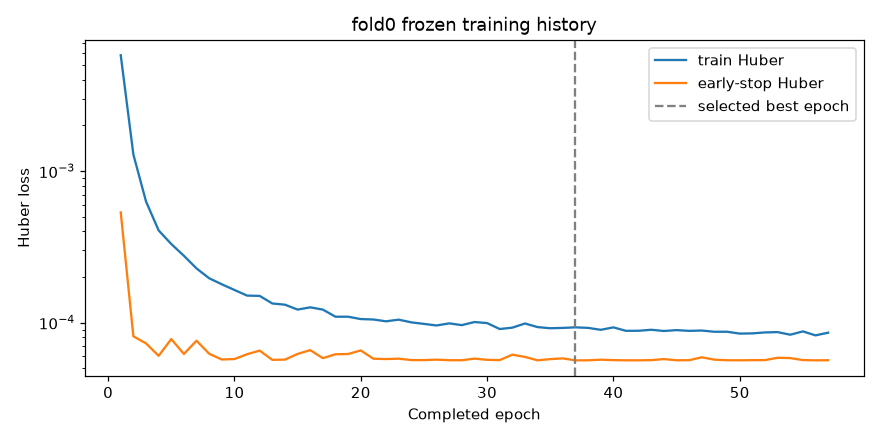

In [2]:
fold0 = history('fold0', 57, 37)

## 18. Fold 1 complete epoch table

fold1 {"best_epoch": 34, "best_es_huber": 3.8186631741155e-05, "fold": 1, "seed": 42001, "termination": "early_stop", "total_epochs": 54}


epoch,train_huber,early_stop_huber,learning_rate,bad_epochs,is_best,elapsed_seconds
1,0.005703,0.000378,0.001000,0,True,0.099
2,0.001087,0.000092,0.001000,0,True,0.246
3,0.000738,0.000058,0.001000,0,True,0.393
4,0.000516,0.000052,0.001000,0,True,0.525
5,0.000357,0.000050,0.001000,0,True,0.649
6,0.000261,0.000042,0.001000,0,True,0.761
7,0.000204,0.000046,0.001000,1,False,0.889
8,0.000166,0.000043,0.001000,2,False,0.984
9,0.000155,0.000040,0.001000,0,True,1.112
10,0.000140,0.000049,0.001000,1,False,1.208


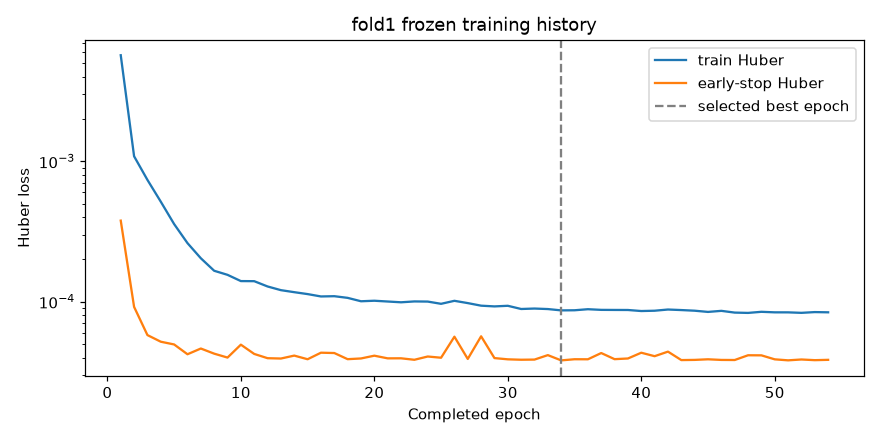

In [3]:
fold1 = history('fold1', 54, 34)

## 19. Fold 2 complete epoch table

fold2 {"best_epoch": 139, "best_es_huber": 5.625082314963947e-05, "fold": 2, "seed": 42002, "termination": "early_stop", "total_epochs": 159}


epoch,train_huber,early_stop_huber,learning_rate,bad_epochs,is_best,elapsed_seconds
1,0.003255,0.000696,0.001000,0,True,0.138
2,0.000719,0.000097,0.001000,0,True,0.272
3,0.000429,0.000141,0.001000,1,False,0.425
4,0.000322,0.000064,0.001000,0,True,0.559
5,0.000245,0.000061,0.001000,0,True,0.710
6,0.000216,0.000096,0.001000,1,False,0.842
7,0.000189,0.000063,0.001000,2,False,0.970
8,0.000167,0.000069,0.001000,3,False,1.103
9,0.000166,0.000087,0.001000,4,False,1.214
10,0.000144,0.000071,0.001000,5,False,1.353


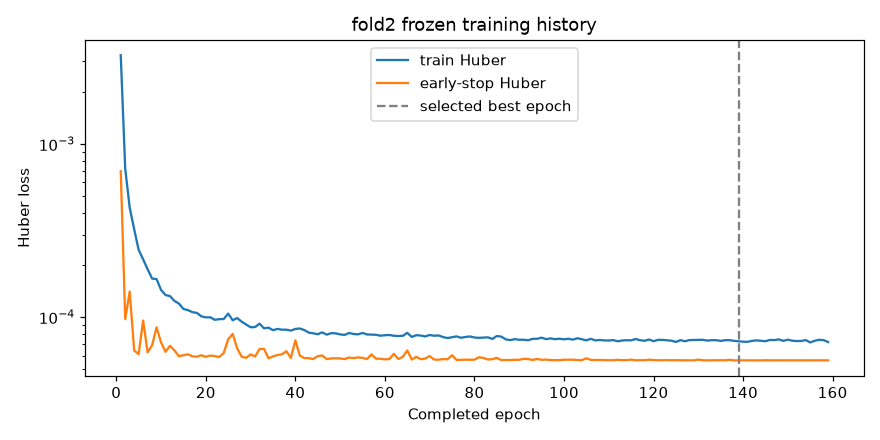

In [4]:
fold2 = history('fold2', 159, 139)

## 110. Fold 3 complete epoch table

fold3 {"best_epoch": 199, "best_es_huber": 4.626554454034704e-05, "fold": 3, "seed": 42003, "termination": "max_epochs", "total_epochs": 200}


epoch,train_huber,early_stop_huber,learning_rate,bad_epochs,is_best,elapsed_seconds
1,0.005194,0.000183,0.001000,0,True,0.105
2,0.001282,0.000144,0.001000,0,True,0.224
3,0.000851,0.000084,0.001000,0,True,0.333
4,0.000598,0.000053,0.001000,0,True,0.443
5,0.000411,0.000073,0.001000,1,False,0.538
6,0.000355,0.000113,0.001000,2,False,0.657
7,0.000296,0.000054,0.001000,3,False,0.752
8,0.000245,0.000051,0.001000,0,True,0.886
9,0.000239,0.000056,0.001000,1,False,0.977
10,0.000209,0.000070,0.001000,2,False,1.091


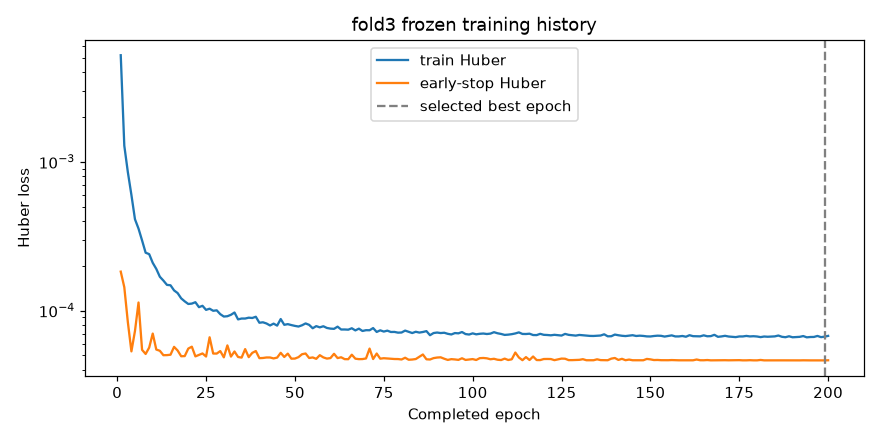

In [5]:
fold3 = history('fold3', 200, 199)

## 111. Fold 4 complete epoch table

fold4 {"best_epoch": 80, "best_es_huber": 7.360472127970752e-05, "fold": 4, "seed": 42004, "termination": "early_stop", "total_epochs": 100}


epoch,train_huber,early_stop_huber,learning_rate,bad_epochs,is_best,elapsed_seconds
1,0.005441,0.000392,0.001000,0,True,0.135
2,0.001166,0.000080,0.001000,0,True,0.285
3,0.000677,0.000139,0.001000,1,False,0.408
4,0.000479,0.000078,0.001000,0,True,0.563
5,0.000328,0.000078,0.001000,0,True,0.703
6,0.000248,0.000088,0.001000,1,False,0.826
7,0.000213,0.000078,0.001000,2,False,0.953
8,0.000187,0.000077,0.001000,0,True,1.090
9,0.000168,0.000077,0.001000,0,True,1.218
10,0.000147,0.000082,0.001000,1,False,1.324


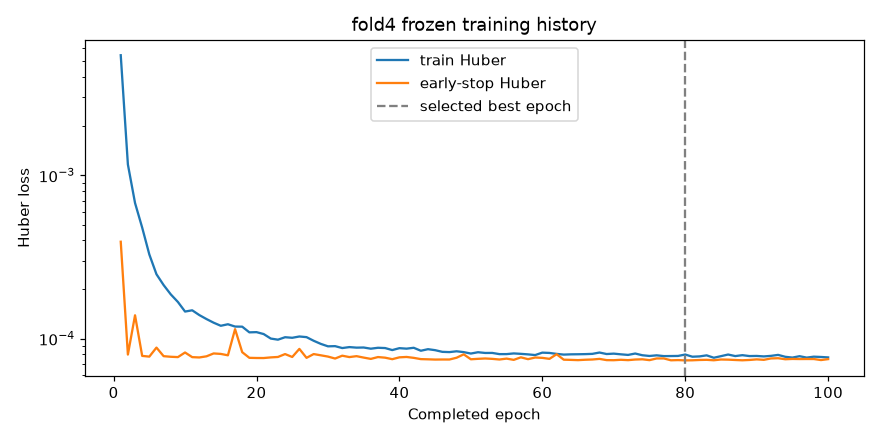

In [6]:
fold4 = history('fold4', 100, 80)

## 22. Five selected best epochs

| fold | best_epoch | best_es_huber | total_epochs | termination |
|---|---|---|---|---|
| 0 | 37 | 5.632870573890614e-05 | 57 | early_stop |
| 1 | 34 | 3.8186631741155e-05 | 54 | early_stop |
| 2 | 139 | 5.625082314963947e-05 | 159 | early_stop |
| 3 | 199 | 4.626554454034704e-05 | 200 | max_epochs |
| 4 | 80 | 7.360472127970752e-05 | 100 | early_stop |

## 23. OOF coverage

4957 rows, 0 missing, 0 duplicates, all finite.

## 24. OOF prediction integrity

All 4957 OOF predictions verified finite. Determinism audit PASS.

## 25. Predicted vs true DeltaDice

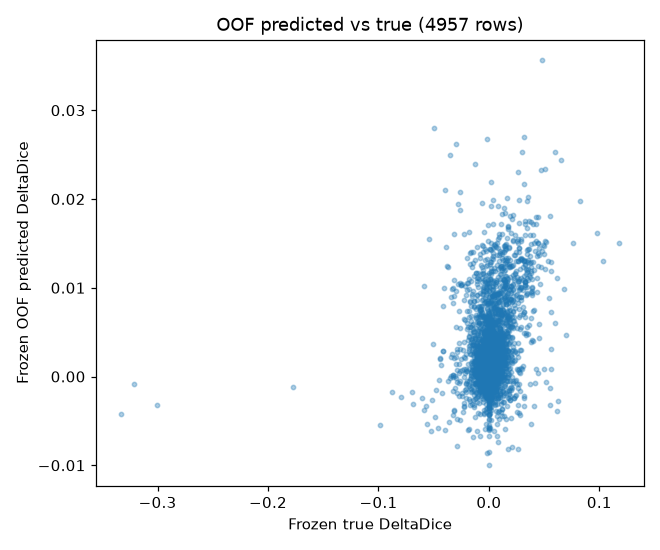

Authoritative frozen OOF R2 = 0.087657630443573 (3 decimals: 0.088; 4: 0.0877; 6: 0.087658)


In [7]:
oof = read_csv('data_cache/phase25d_barr_benefit_router_v1_2_1/phase25d_oof_router_predictions.csv')
assert len(oof) == 4957 and oof.sample_id.nunique() == 4957
assert np.isfinite(oof.select_dtypes(include='number').to_numpy()).all()
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(oof.delta_dice, oof.delta_hat_oof, s=8, alpha=0.35)
ax.set(xlabel='Frozen true DeltaDice', ylabel='Frozen OOF predicted DeltaDice', title='OOF predicted vs true (4957 rows)')
fig.tight_layout(); figure(fig)
freeze = read_json('reports/audits/phase25d_final_freeze.json')
assert freeze['oof_r2'] == 0.087657630443573
print('Authoritative frozen OOF R2 = 0.087657630443573 (3 decimals: 0.088; 4: 0.0877; 6: 0.087658)')

## 26. Overall regression metrics

| metric | value |
|---|---|
| huber | 7.112138700904325e-05 |
| mae | 0.006642347667366266 |
| rmse | 0.013814026489853859 |
| pearson | 0.29962822794914246 |
| spearman | 0.21394063290695958 |
| r2 | 0.087657630443573 |

## 27. Per-domain metrics

| domain | huber | mae | rmse | pearson | spearman | r2 |
|---|---|---|---|---|---|---|
| KVASIR | 3.2185946565732593e-06 | 0.0015764139825478196 | 0.0025371615774929523 | -0.039820656180381775 | -0.008959769127033574 | -0.39362967014312744 |
| ISIC | 2.8332662623142824e-05 | 0.004764263518154621 | 0.007558337412774563 | 0.15809015929698944 | 0.13417320390692888 | 0.007339119911193848 |
| BUSI | 2.436577005937579e-06 | 0.001626220066100359 | 0.0022075222805142403 | 0.002840244211256504 | -0.008693698429864616 | -0.32928597927093506 |
| KUB | 0.00017132672655861825 | 0.012385420501232147 | 0.02203197218477726 | 0.3061244487762451 | 0.3188041796047271 | 0.09026294946670532 |

## 28. Per-fold metrics

| fold | huber | mae | rmse | pearson | spearman | r2 |
|---|---|---|---|---|---|---|
| fold0 | 7.373146218014881e-05 | 0.006942798383533955 | 0.012470555491745472 | 0.29495611786842346 | 0.15087166134141852 | 0.08381915092468262 |
| fold1 | 7.313333480851725e-05 | 0.006751617416739464 | 0.0148715665563941 | 0.3722846508026123 | 0.2635643358278358 | 0.11931735277175903 |
| fold2 | 6.312203913694248e-05 | 0.006408013869076967 | 0.011274347081780434 | 0.31516051292419434 | 0.230563989406907 | 0.09613895416259766 |
| fold3 | 8.643574255984277e-05 | 0.006659763865172863 | 0.017774563282728195 | 0.27766677737236023 | 0.28863660118418455 | 0.07614147663116455 |
| fold4 | 5.917968155699782e-05 | 0.006449128966778517 | 0.011593857780098915 | 0.27409857511520386 | 0.16098927330585666 | 0.052816808223724365 |

## 29. Residual analysis

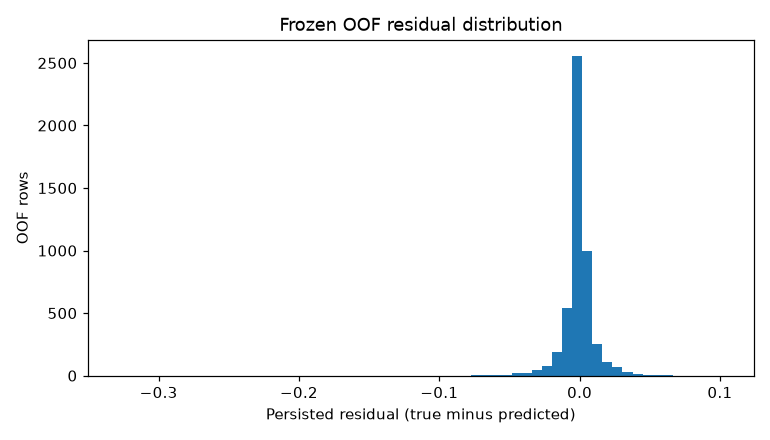

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(oof.residual, bins=60)
ax.set(xlabel='Persisted residual (true minus predicted)', ylabel='OOF rows', title='Frozen OOF residual distribution')
fig.tight_layout(); figure(fig)

## 30. Secondary beneficial discrimination

Classification: `SECONDARY_DESCRIPTIVE__NO_THRESHOLD_SELECTION`

| comparison | roc_auc | pr_auc |
|---|---|---|
| beneficial_vs_rest | 0.8137012174308795 | 0.3487565890819809 |
| harmful_vs_rest | 0.5319871865251845 | 0.09651033297792833 |

## 31. Secondary harmful discrimination

(Same table as above -- no threshold selected.)

## 32. Interpretation discipline

Phase25C shows strongly heterogeneous paired refinement gain. Most samples neutral, both beneficial and harmful cases exist. Aggregate behaviour belongs to Phase22.

## 33. Exact median final-epoch rule

Best epochs: [37, 34, 139, 199, 80]
Sorted: [34, 37, 80, 139, 199]
**FINAL_ROUTER_EPOCHS = 80**

## 34. Final normalization

Fitted on ALL 4957 DEV rows. Persisted in final checkpoint.

## 35. Final refit complete epoch table

epoch,train_huber,learning_rate,elapsed_seconds
1,0.003679,0.0010,0.167
2,0.000609,0.0010,0.311
3,0.000359,0.0010,0.479
4,0.000257,0.0010,0.624
5,0.000192,0.0010,0.781
6,0.000168,0.0010,0.941
7,0.000152,0.0010,1.086
8,0.000143,0.0010,1.227
9,0.000127,0.0010,1.378
10,0.000121,0.0010,1.511


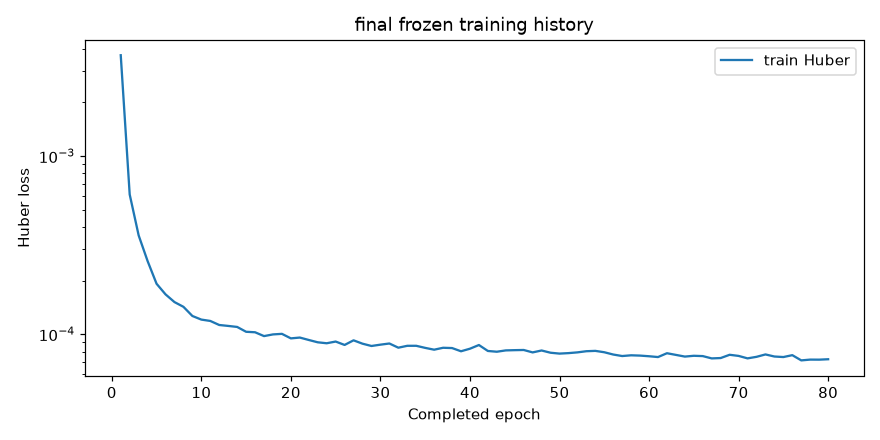

checkpoint rule = LAST_FIXED_EPOCH; checkpoint epoch = 80; final history rows = 80


In [9]:
final = history('final', 80)
freeze = read_json('reports/audits/phase25d_final_freeze.json')
rule = read_json('reports/audits/phase25d_final_refit_epoch_rule_execution.json')
assert rule['best_epochs'] == [37, 34, 139, 199, 80]
assert rule['final_router_epochs'] == freeze['final_router_epochs'] == int(final.epoch.iloc[-1]) == 80
assert sorted(rule['best_epochs'])[2] == 80
print('checkpoint rule = LAST_FIXED_EPOCH; checkpoint epoch = 80; final history rows = 80')

## 36. Final checkpoint

`checkpoints/phase25d_barr_benefit_router_v1_2_1_seed42/final/final.pt`

- Parameter count: 36801
- State dict load: PASS
- Synthetic inference: PASS

These checkpoint integrity and synthetic-inference results are historical frozen audit evidence; this notebook performs no model loading or inference.

## 37. Compute bookkeeping

Router Linear MACs per sample: ~31k (218x128 + 128x64 + 64x1).

## 38. No lambda assertion

**lambda NOT selected.** Phase25D does not execute resource-gate calibration.

## 39. No gate-threshold assertion

**Routing threshold NOT calibrated.**

## 40. No holdout assertion

**ROUTER_HOLDOUT reads = 0.**

## 41. No VAL808 assertion

**VAL808 reads = 0.**

## 42. No TEST assertion

**TEST reads = 0.**

## 43. Phase25E handoff

Phase25D provides: final checkpoint, normalization stats, task registry, 4957 OOF predictions, paired labels, feature schema, CV provenance.

Phase25E owns: resource cost C, lambda grid, U_hat, activation gate, budget analysis, threshold semantics.

## 44. Final assertions

- Reentry gate: PASS
- Architecture: 36801 params exact
- 5 CV runs complete
- OOF: 4957 rows, all finite
- Final refit: 80 epochs fixed
- Notebook: 0 errors
- Test reads: 0
- Phase25E: NOT started

In [10]:
assert [len(fold0), len(fold1), len(fold2), len(fold3), len(fold4)] == [57,54,159,200,100]
assert len(final) == 80
for key in ['lambda_selected', 'routing_threshold_selected', 'resource_gate_calibrated', 'phase25e_started']:
    assert freeze[key] is False
for key in ['router_holdout_reads', 'val808_reads', 'test_reads']:
    assert freeze[key] == 0
print('RUN_ALL_COMPLETE: all frozen-artifact, full-history and scope assertions passed.')
print('Phase25D COMPLETE_CANONICAL / TRAINED_FROZEN; Phase25E ELIGIBLE_NOT_STARTED')

RUN_ALL_COMPLETE: all frozen-artifact, full-history and scope assertions passed.
Phase25D COMPLETE_CANONICAL / TRAINED_FROZEN; Phase25E ELIGIBLE_NOT_STARTED
